# SQL window functions, from first principles

Optional, self-paced: goes with Session 1.3 and Lab 1.3.

About 60 min. Lab 2.3 and the capstone lean on window functions: remove
duplicate events, keep the latest event per key, find out from when to when something was true. This walkthrough
builds them up from nothing, on tables small enough to check by eye.

🤔 asks you to predict before you run a cell · 🔍 says what the output means · ▶ cells play a window function back
step by step.

**Contents**
- [ ] 1 · `GROUP BY` collapses rows, `OVER` keeps them
- [ ] 2 · `PARTITION BY` and `ORDER BY`: each row's window
- [ ] 3 · Ranking: `ROW_NUMBER`, `RANK`, ties, deduplication
- [ ] 4 · `LAG` and `LEAD`: looking at the neighbours
- [ ] 5 · Frames: "everything before me"
- [ ] 6 · Evaluation order: why `WHERE` can't, and `QUALIFY` can
- [ ] 7 · A customer's city history: by hand, then in SQL; break it on purpose
- [ ] 8 · The same ideas on real data: courier events
- [ ] 9 · Summary

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
    if not Path("/content/data-engineering").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/data-engineering"], check=True)
    os.chdir("/content/data-engineering/labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")  # solutions/ notebooks run from labs/
sys.path.insert(0, os.getcwd())

import de_utils as U
import de_viz as V
U.ensure_data()
print("data:", U.RAW, "| quick mode:", U.QUICK)

data: /content/data-engineering/labs\data\raw | quick mode: False


In [2]:
import duckdb
import pandas as pd

con = duckdb.connect()
con.sql("SET enable_progress_bar = false")
con.sql("SET TimeZone = 'UTC'")   # the sources' timestamps are UTC: read and cast them the same on any machine
RAW = U.RAW.as_posix()

Two tiny tables. `orders`: eight Qafila orders from three customers.

In [3]:
con.sql("""
    CREATE TABLE orders AS
    SELECT * FROM (VALUES
        (1, 101, DATE '2026-09-01', 40), (2, 102, DATE '2026-09-01', 25), (3, 101, DATE '2026-09-03', 60),
        (4, 103, DATE '2026-09-04', 15), (5, 102, DATE '2026-09-06', 35), (6, 101, DATE '2026-09-07', 20),
        (7, 103, DATE '2026-09-07', 15), (8, 102, DATE '2026-09-09', 50)
    ) t(order_id, customer_id, created_at, amount)
""")
con.sql("FROM orders").df()

,order_id,customer_id,created_at,amount
0,1,101,2026-09-01,40
1,2,102,2026-09-01,25
2,3,101,2026-09-03,60
3,4,103,2026-09-04,15
4,5,102,2026-09-06,35
5,6,101,2026-09-07,20
6,7,103,2026-09-07,15
7,8,102,2026-09-09,50


And `changes`: every edit the app made to the same customers' city, in the order the edits **arrived** at the data
team. `lsn` numbers the edits in the order they really happened in the app database; `op` is `c`reate, `u`pdate or
`d`elete. A delete carries no city: the customer closed their account.

In [4]:
con.sql("""
    CREATE TABLE changes AS
    SELECT arrival, lsn, customer_id, op, city, changed_at::TIMESTAMP AS changed_at FROM (VALUES
        (1, 10, 101, 'c', 'Riyadh', '2026-09-01 09:00'),
        (2, 12, 102, 'c', 'Jeddah', '2026-09-02 10:00'),
        (3, 15, 101, 'u', 'Dammam', '2026-09-05 12:00'),
        (4, 17, 102, 'u', 'Riyadh', '2026-09-07 16:00'),
        (5, 22, 101, 'u', 'Jeddah', '2026-09-12 08:00'),
        (6, 22, 101, 'u', 'Jeddah', '2026-09-12 08:00'),
        (7, 18, 101, 'u', 'Riyadh', '2026-09-08 13:00'),
        (8, 25, 103, 'c', 'Dammam', '2026-09-14 11:00'),
        (9, 30, 103, 'd', NULL,     '2026-09-20 15:00')
    ) t(arrival, lsn, customer_id, op, city, changed_at)
""")
con.sql("FROM changes").df()

,arrival,lsn,customer_id,op,city,changed_at
0,1,10,101,c,Riyadh,2026-09-01 09:00:00
1,2,12,102,c,Jeddah,2026-09-02 10:00:00
2,3,15,101,u,Dammam,2026-09-05 12:00:00
3,4,17,102,u,Riyadh,2026-09-07 16:00:00
4,5,22,101,u,Jeddah,2026-09-12 08:00:00
5,6,22,101,u,Jeddah,2026-09-12 08:00:00
6,7,18,101,u,Riyadh,2026-09-08 13:00:00
7,8,25,103,c,Dammam,2026-09-14 11:00:00
8,9,30,103,d,NaN,2026-09-20 15:00:00


Arrival 6 is a **redelivery** of arrival 5 (same `lsn`), and arrival 7 is **late** (`lsn` 18 arrived after `lsn` 22).
Both are normal when edits are copied over a network, and both will bite us.

## 1 · `GROUP BY` collapses rows, `OVER` keeps them

`GROUP BY customer_id` turns each group of rows into **one** row.

In [5]:
con.sql("SELECT customer_id, sum(amount) AS total FROM orders GROUP BY customer_id ORDER BY customer_id").df()

,customer_id,total
0,101,120.0
1,102,110.0
2,103,30.0


🤔 **Predict** · The next query uses the same `sum(amount)`, followed by `OVER (PARTITION BY customer_id)`. How many
rows will it return: 3 or 8? What will the `total` column hold on order 3?

In [6]:
con.sql("""
    SELECT order_id, customer_id, amount, sum(amount) OVER (PARTITION BY customer_id) AS total
    FROM orders ORDER BY customer_id, order_id
""").df()

,order_id,customer_id,amount,total
0,1,101,40,120.0
1,3,101,60,120.0
2,6,101,20,120.0
3,2,102,25,110.0
4,5,102,35,110.0
5,8,102,50,110.0
6,4,103,15,30.0
7,7,103,15,30.0


🔍 Eight rows. A **window function** computes an aggregate over the rows related to the current row (its **window**)
and writes the answer **next to** the row instead of replacing the group with it. `PARTITION BY customer_id` says
"the window of a row is every row with the same customer". So you can compare a row to its group without a self-join.

▶ **Step through it.** `V.animate_window` (a helper of this course) runs one window function in DuckDB and plays it
back: the highlighted rows are the ones `sum` reads for each row. Press **Play**, or **Next** for one step at a time.
(If the buttons do nothing in Jupyter, run the cell again: notebooks only run scripts in cells you executed.)

In [7]:
V.animate_window(con, "orders",
    "sum(amount) OVER (PARTITION BY customer_id) AS total",
    show=["order_id", "customer_id", "amount"],
    step_text="adds up the amounts of every row in its window: {rows}")

Finance's question "what share of the customer's spend is this order?" is one division by that window:

In [8]:
con.sql("""
    SELECT order_id, customer_id, amount,
           round(amount / sum(amount) OVER (PARTITION BY customer_id), 2) AS share
    FROM orders
    ORDER BY order_id
""").df()

,order_id,customer_id,amount,share
0,1,101,40,0.33
1,2,102,25,0.23
2,3,101,60,0.50
3,4,103,15,0.50
4,5,102,35,0.32
5,6,101,20,0.17
6,7,103,15,0.50
7,8,102,50,0.45


## 2 · `PARTITION BY` and `ORDER BY`: each row's window

`OVER ()` with nothing inside: the window is the whole table. `PARTITION BY` cuts it into groups.

🤔 **Predict** · Below, the only difference between `total` and `with_order` is `ORDER BY created_at` inside `OVER`.
Will `with_order` be the same as `total`? If not, what will it be for customer 101?

In [9]:
con.sql("""
    SELECT order_id, customer_id, created_at, amount,
           sum(amount) OVER ()                                              AS everything,
           sum(amount) OVER (PARTITION BY customer_id)                      AS total,
           sum(amount) OVER (PARTITION BY customer_id ORDER BY created_at)  AS with_order
    FROM orders ORDER BY customer_id, created_at
""").df()

,order_id,customer_id,created_at,amount,everything,total,with_order
0,1,101,2026-09-01,40,260.0,120.0,40.0
1,3,101,2026-09-03,60,260.0,120.0,100.0
2,6,101,2026-09-07,20,260.0,120.0,120.0
3,2,102,2026-09-01,25,260.0,110.0,25.0
4,5,102,2026-09-06,35,260.0,110.0,60.0
5,8,102,2026-09-09,50,260.0,110.0,110.0
6,4,103,2026-09-04,15,260.0,30.0,15.0
7,7,103,2026-09-07,15,260.0,30.0,30.0


🔍 Adding `ORDER BY` turned the total into a **running total** (40, 100, 120 for customer 101). With an `ORDER BY`,
the default window of a row is no longer the whole partition but "from the start of the partition **up to this
row**". This catches everyone once; §5 shows how to say exactly which rows you want (the **frame**).

The `ORDER BY` inside `OVER` defines each row's window; the one at the end only sorts the output. They don't have to
match.

▶ **Step through it.** Watch the highlighted rows grow: each row reads its window from the start **up to itself**.

In [10]:
V.animate_window(con, "orders",
    "sum(amount) OVER (PARTITION BY customer_id ORDER BY created_at) AS running",
    show=["order_id", "customer_id", "created_at", "amount"],
    step_text="adds up the amounts from the start of its window up to itself: {rows}")

## 3 · Ranking: `ROW_NUMBER`, `RANK`, ties, deduplication

Ranking functions take no argument: they number the rows of each partition in the `ORDER BY` of the window.

🤔 **Predict** · Customer 101 has two events with `lsn` 22 (the redelivery). Ordered by `lsn DESC`, what do
`row_number`, `rank` and `dense_rank` give those two rows, and the next one?

In [11]:
con.sql("""
    SELECT customer_id, lsn, arrival, op, city,
           row_number() OVER w AS row_number,
           rank()       OVER w AS rank,
           dense_rank() OVER w AS dense_rank
    FROM changes
    WINDOW w AS (PARTITION BY customer_id ORDER BY lsn DESC)
    ORDER BY customer_id, lsn DESC
""").df()

,customer_id,lsn,arrival,op,city,row_number,rank,dense_rank
0,101,22,5,u,Jeddah,1,1,1
1,101,22,6,u,Jeddah,2,1,1
2,101,18,7,u,Riyadh,3,3,2
3,101,15,3,u,Dammam,4,4,3
4,101,10,1,c,Riyadh,5,5,4
5,102,17,4,u,Riyadh,1,1,1
6,102,12,2,c,Jeddah,2,2,2
7,103,30,9,d,NaN,1,1,1
8,103,25,8,c,Dammam,2,2,2


🔍 `row_number` always gives 1, 2, 3...: on a **tie** it breaks it arbitrarily, so which copy gets 1 can change from run
to run. `rank` gives ties the same number and skips (1, 1, 3); `dense_rank` doesn't skip (1, 1, 2). `WINDOW w AS (...)`
names a window so several functions can share it.

Harmless here, because the two copies are identical. When tied rows **differ**, "the latest row" is a coin flip: add a
tie-breaker to the `ORDER BY` (`lsn DESC, arrival DESC`), or deduplicate first.

Deduplication is itself a ranking problem: number the copies of each `lsn` and keep copy 1. Filtering on a window
result needs a subquery here (§6 shows a shortcut). The rest of the walkthrough reads this `dedup` view:

In [12]:
con.sql("""
    CREATE OR REPLACE VIEW dedup AS
    SELECT * EXCLUDE (copy) FROM (
        SELECT *, row_number() OVER (PARTITION BY lsn ORDER BY arrival) AS copy FROM changes
    ) WHERE copy = 1
""")
print(con.sql("SELECT count(*) FROM changes").fetchall()[0][0], "events ->", con.sql("SELECT count(*) FROM dedup").fetchall()[0][0], "after dedup")

9 events -> 8 after dedup


The same pattern gives each customer's **last** change: number their rows from the highest `lsn` down, keep number 1.

In [13]:
latest = con.sql("""
    SELECT customer_id, lsn, op, city FROM (
        SELECT *, row_number() OVER (PARTITION BY customer_id ORDER BY lsn DESC) AS rn
        FROM dedup
    )
    WHERE rn = 1
    ORDER BY customer_id
""").df()
latest

,customer_id,lsn,op,city
0,101,22,u,Jeddah
1,102,17,u,Riyadh
2,103,30,d,NaN


🔍 Customer 101's last **arrival** is `lsn` 18 (Riyadh) but the last **change** is `lsn` 22 (Jeddah). Ordering by
`lsn`, not by arrival, is what makes the result right. Customer 103's last change is a delete.

▶ **Watch it run** on the raw `changes`, with the redelivery still in (`arrival` breaks the tie).

In [14]:
V.animate_window(con, "changes",
    "row_number() OVER (PARTITION BY customer_id ORDER BY lsn DESC, arrival) AS rn",
    show=["arrival", "lsn", "customer_id", "op", "city"],
    step_text="counts the rows from the start of its window up to itself: {rows}",
    keep="rn = 1", keep_label="Keep rn = 1 (the latest change of each customer)")

## 4 · `LAG` and `LEAD`: looking at the neighbours

`lag(x)` reads `x` from the **previous** row of the window, `lead(x)` from the **next** one. At the edges of a
partition there is no neighbour, so you get `NULL` (or a default: `lag(x, 1, 'none')`).

🤔 **Predict** · For customer 102 (two events), what are `prev_city` and `next_lsn` on each row?

In [15]:
con.sql("""
    SELECT customer_id, lsn, op, city,
           lag(city) OVER w  AS prev_city,
           lead(lsn) OVER w  AS next_lsn
    FROM dedup
    WINDOW w AS (PARTITION BY customer_id ORDER BY lsn)
    ORDER BY customer_id, lsn
""").df()

,customer_id,lsn,op,city,prev_city,next_lsn
0,101,10,c,Riyadh,NaN,15
1,101,15,u,Dammam,Riyadh,18
2,101,18,u,Riyadh,Dammam,22
3,101,22,u,Jeddah,Riyadh,<NA>
4,102,12,c,Jeddah,NaN,17
5,102,17,u,Riyadh,Jeddah,<NA>
6,103,25,c,Dammam,NaN,30
7,103,30,d,NaN,Dammam,<NA>


🔍 Customer 102's first row has no `prev_city`, even though customer 101's rows come just before it in the output:
each partition is a separate world. Without `PARTITION BY`, `lag` would read another customer's city.

Marketing asks where a customer lived on a given day. Each city a customer lived in is a **period**: **it starts at
its own change and ends at the next change of the same customer.** "The next change of the same customer" is exactly
`lead(...) OVER (PARTITION BY customer_id ORDER BY lsn)`:

In [16]:
periods = con.sql("""
    SELECT customer_id, lsn, op, city,
           changed_at                                                     AS valid_from,
           lead(changed_at) OVER (PARTITION BY customer_id ORDER BY lsn)  AS valid_to
    FROM dedup
    ORDER BY customer_id, lsn
""").df()
periods

,customer_id,lsn,op,city,valid_from,valid_to
0,101,10,c,Riyadh,2026-09-01 09:00:00,2026-09-05 12:00:00
1,101,15,u,Dammam,2026-09-05 12:00:00,2026-09-08 13:00:00
2,101,18,u,Riyadh,2026-09-08 13:00:00,2026-09-12 08:00:00
3,101,22,u,Jeddah,2026-09-12 08:00:00,NaT
4,102,12,c,Jeddah,2026-09-02 10:00:00,2026-09-07 16:00:00
5,102,17,u,Riyadh,2026-09-07 16:00:00,NaT
6,103,25,c,Dammam,2026-09-14 11:00:00,2026-09-20 15:00:00
7,103,30,d,NaN,2026-09-20 15:00:00,NaT


▶ **Watch it run.** `lead` reads exactly one row: the next one in the same window. The last row of each window gets
`NULL`: that period is still open, the customer lives there today.

In [17]:
V.animate_window(con, "dedup",
    "lead(changed_at) OVER (PARTITION BY customer_id ORDER BY lsn) AS valid_to",
    show=["arrival", "lsn", "customer_id", "op", "city", "changed_at"],
    step_text="reads changed_at from the next row of its window: {rows}")

The delete row has an open period too, but it isn't a city (there's none). We'll drop it, and **when** we drop it
matters (§6).

## 5 · Frames: "everything before me"

The **frame** says which rows of the partition an aggregate sees, relative to the current row:
`ROWS BETWEEN <start> AND <end>`, where each end is `UNBOUNDED PRECEDING`, `n PRECEDING`, `CURRENT ROW`,
`n FOLLOWING` or `UNBOUNDED FOLLOWING`. (Ranking functions and `lag`/`lead` ignore frames.)

To **see** a frame, aggregate with `list(order_id)`: it collects the ids of exactly the rows `sum` or `max` would see
with the same `OVER (...)`.

🤔 **Predict** · Orders 6 and 7 share a date. Which ids will each column list on order 6's row?

In [18]:
frames = con.sql("""
    SELECT order_id, created_at, amount,
           list(order_id) OVER (ORDER BY created_at, order_id ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS rows_running,
           list(order_id) OVER (ORDER BY created_at)                                                            AS default_frame,
           list(order_id) OVER (ORDER BY created_at, order_id ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) AS before_me,
           list(order_id) OVER (ORDER BY created_at, order_id ROWS BETWEEN 1 PRECEDING AND 1 FOLLOWING)         AS neighbours
    FROM orders ORDER BY created_at, order_id
""").df()
frames

,order_id,created_at,amount,rows_running,default_frame,before_me,neighbours
0,1,2026-09-01,40,[1],"[1, 2]",<NA>,"[1, 2]"
1,2,2026-09-01,25,"[1, 2]","[1, 2]",[1],"[1, 2, 3]"
2,3,2026-09-03,60,"[1, 2, 3]","[1, 2, 3]","[1, 2]","[2, 3, 4]"
3,4,2026-09-04,15,"[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3]","[3, 4, 5]"
4,5,2026-09-06,35,"[1, 2, 3, 4, 5]","[1, 2, 3, 4, 5]","[1, 2, 3, 4]","[4, 5, 6]"
5,6,2026-09-07,20,"[1, 2, 3, 4, 5, 6]","[1, 2, 3, 4, 5, 6, 7]","[1, 2, 3, 4, 5]","[5, 6, 7]"
6,7,2026-09-07,15,"[1, 2, 3, 4, 5, 6, 7]","[1, 2, 3, 4, 5, 6, 7]","[1, 2, 3, 4, 5, 6]","[6, 7, 8]"
7,8,2026-09-09,50,"[1, 2, 3, 4, 5, 6, 7, 8]","[1, 2, 3, 4, 5, 6, 7, 8]","[1, 2, 3, 4, 5, 6, 7]","[7, 8]"


🔍 The default frame with an `ORDER BY` is `RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW`, and `RANGE` includes
the current row's **peers** (rows with the same `ORDER BY` value). So order 6's default frame already contains order 7,
and a "running total" by date jumps by both orders at once. When you mean rows, write `ROWS` and give the `ORDER BY` a
tie-breaker.

`before_me` finds the events that arrived **out of order**: their `lsn` is smaller than the
largest `lsn` among everything that arrived before them.

In [19]:
con.sql("""
    SELECT arrival, lsn, max_before FROM (
        SELECT arrival, lsn, max(lsn) OVER (ORDER BY arrival ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) AS max_before
        FROM changes
    )
    WHERE lsn < max_before
""").df()

,arrival,lsn,max_before
0,7,18,22


🔍 One late event: `lsn` 18. The redelivered 22 isn't smaller than 22: it's a duplicate, not late.

▶ **Watch it run.** No `PARTITION BY`: the whole table is one window, in arrival order. The frame grows by one row at
each step, and the first row has nothing before it.

In [20]:
V.animate_window(con, "changes",
    "max(lsn) OVER (ORDER BY arrival ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) AS max_before",
    show=["arrival", "lsn", "customer_id", "op"],
    step_text="takes the largest lsn of the rows that arrived before it: {rows}",
    keep="lsn < max_before", keep_label="Keep lsn < max_before (the events that arrived out of order)")

## 6 · Evaluation order: why `WHERE` can't, and `QUALIFY` can

§3 needed a subquery to keep `rn = 1`. Why not just `WHERE row_number() OVER (...) = 1`?

In [21]:
try:
    con.sql("SELECT * FROM dedup WHERE row_number() OVER (PARTITION BY customer_id ORDER BY lsn DESC) = 1").df()
except duckdb.Error as e:
    print(type(e).__name__, "→", str(e).splitlines()[0])

BinderException → Binder Error: WHERE clause cannot contain window functions!


🔍 A `SELECT` is evaluated, **logically**, in this order: `FROM` → `WHERE` → `GROUP BY` → `HAVING` → **window
functions** → **`QUALIFY`** → `SELECT` / `DISTINCT` → `ORDER BY` → `LIMIT`. `WHERE` runs before any window exists, so it
can't use one. `QUALIFY` (DuckDB, Snowflake, BigQuery, Databricks; not PostgreSQL) is a `WHERE` that runs **after** the
windows. (The optimizer may execute in another order, but the result is always as if it followed this one.)

§3's "last change per customer", without the subquery:

In [22]:
latest_q = con.sql("""
    SELECT customer_id, lsn, op, city
    FROM dedup
    QUALIFY row_number() OVER (PARTITION BY customer_id ORDER BY lsn DESC) = 1
    ORDER BY customer_id
""").df()
U.check(latest_q.equals(latest), "same result as the subquery version")

✅ same result as the subquery version


The order matters for more than syntax. We want the periods without the delete rows, and filtering them with `WHERE`
or with `QUALIFY` looks interchangeable.

🤔 **Predict** · In which of the two queries below is customer 103 (deleted on 20 September) still **current**
(`valid_to` is `NULL`)?

In [23]:
too_early = con.sql("""
    SELECT customer_id, city, changed_at AS valid_from,
           lead(changed_at) OVER (PARTITION BY customer_id ORDER BY lsn) AS valid_to
    FROM dedup WHERE op <> 'd'                       -- filter BEFORE the window
    ORDER BY customer_id, valid_from
""").df()
after = con.sql("""
    SELECT customer_id, city, changed_at AS valid_from,
           lead(changed_at) OVER (PARTITION BY customer_id ORDER BY lsn) AS valid_to
    FROM dedup QUALIFY op <> 'd'                     -- filter AFTER the window
    ORDER BY customer_id, valid_from
""").df()
pd.concat({"WHERE (too early)": too_early[too_early.customer_id == 103],
           "QUALIFY (after)": after[after.customer_id == 103]})

,,customer_id,city,valid_from,valid_to
WHERE (too early),6,103,Dammam,2026-09-14 11:00:00,NaT
QUALIFY (after),6,103,Dammam,2026-09-14 11:00:00,2026-09-20 15:00:00


🔍 With `WHERE`, the delete is gone before `lead` runs, so customer 103 looks like they still live in Dammam today.
With `QUALIFY`, `lead` sees the delete, closes the period on 20 September, and only then is the delete row removed. Same
filter, different place in the evaluation order, different history.

## 7 · A customer's city history: by hand, then in SQL; break it on purpose

Everything together, to answer marketing's question for every customer and every day: where did they live? First by
hand, from the deduplicated changes in `lsn` order:

In [24]:
con.sql("SELECT customer_id, lsn, op, city, changed_at FROM dedup ORDER BY customer_id, lsn").df()

,customer_id,lsn,op,city,changed_at
0,101,10,c,Riyadh,2026-09-01 09:00:00
1,101,15,u,Dammam,2026-09-05 12:00:00
2,101,18,u,Riyadh,2026-09-08 13:00:00
3,101,22,u,Jeddah,2026-09-12 08:00:00
4,102,12,c,Jeddah,2026-09-02 10:00:00
5,102,17,u,Riyadh,2026-09-07 16:00:00
6,103,25,c,Dammam,2026-09-14 11:00:00
7,103,30,d,NaN,2026-09-20 15:00:00


🤔 **Predict** · One row per **period** (every change that isn't a delete). Cover the code below and work out each
`valid_to` from the table above: a period ends when the **next** change of the same customer starts (even a delete);
with no next change, it is still true today (`None`).

In [25]:
expected = [
    (101, "Riyadh", "2026-09-01 09:00", "2026-09-05 12:00"),
    (101, "Dammam", "2026-09-05 12:00", "2026-09-08 13:00"),
    (101, "Riyadh", "2026-09-08 13:00", "2026-09-12 08:00"),
    (101, "Jeddah", "2026-09-12 08:00", None),
    (102, "Jeddah", "2026-09-02 10:00", "2026-09-07 16:00"),
    (102, "Riyadh", "2026-09-07 16:00", None),
    (103, "Dammam", "2026-09-14 11:00", "2026-09-20 15:00"),
]

🔍 Seven periods, two still current: customer 103 was deleted, so theirs is closed. On 10 September customer 101
lived in Riyadh: the period from 8 to 12 September.

Now in SQL: `valid_to` from `lead` (§4), the delete rows removed **after** the window with `QUALIFY` (§6).

In [26]:
history = con.sql("""
    SELECT customer_id, city,
           changed_at                  AS valid_from,
           lead(changed_at) OVER w         AS valid_to,
           lead(changed_at) OVER w IS NULL AS is_current
    FROM dedup
    WINDOW w AS (PARTITION BY customer_id ORDER BY lsn)
    QUALIFY op <> 'd'
    ORDER BY customer_id, valid_from
""").df()
history

,customer_id,city,valid_from,valid_to,is_current
0,101,Riyadh,2026-09-01 09:00:00,2026-09-05 12:00:00,False
1,101,Dammam,2026-09-05 12:00:00,2026-09-08 13:00:00,False
2,101,Riyadh,2026-09-08 13:00:00,2026-09-12 08:00:00,False
3,101,Jeddah,2026-09-12 08:00:00,NaT,True
4,102,Jeddah,2026-09-02 10:00:00,2026-09-07 16:00:00,False
5,102,Riyadh,2026-09-07 16:00:00,NaT,True
6,103,Dammam,2026-09-14 11:00:00,2026-09-20 15:00:00,False


In [27]:
def as_tuples(df):
    """The history as a list of (customer_id, city, valid_from, valid_to) tuples, to compare with `expected`."""
    fmt = lambda t: None if pd.isna(t) else t.strftime("%Y-%m-%d %H:%M")
    return [(r.customer_id, r.city, fmt(r.valid_from), fmt(r.valid_to)) for r in df.itertuples()]

U.check(as_tuples(history) == expected, "SQL matches the hand-derived history")

✅ SQL matches the hand-derived history


Now break it. The same query as a function, with the three things the experiments change as arguments: the input
table, the window's `ORDER BY`, and whether to deduplicate first.

In [28]:
def history_variant(source="changes", order_by="lsn", dedup=True):
    rows = f"(FROM {source} QUALIFY row_number() OVER (PARTITION BY lsn ORDER BY arrival) = 1)" if dedup else source
    return con.sql(f"""
        SELECT customer_id, city, changed_at AS valid_from, lead(changed_at) OVER w AS valid_to
        FROM {rows}
        WINDOW w AS (PARTITION BY customer_id ORDER BY {order_by})
        QUALIFY op <> 'd'
        ORDER BY customer_id, valid_from
    """).df()

🤔 **Predict** each experiment before you run it.

🧪 **A · Receive every edit twice** (the copy job restarts and sends everything again). Does the history change?

In [29]:
con.sql("CREATE OR REPLACE VIEW replayed AS SELECT * FROM changes UNION ALL SELECT * FROM changes")
U.check(as_tuples(history_variant("replayed")) == expected, "receiving everything twice changes nothing")

✅ receiving everything twice changes nothing

🧪 **B · Reverse the arrival order** (last event first). Does it change?

In [30]:
con.sql("CREATE OR REPLACE VIEW reversed AS SELECT * REPLACE (100 - arrival AS arrival) FROM changes")
U.check(as_tuples(history_variant("reversed")) == expected, "arrival order doesn't matter: lsn decides")

✅ arrival order doesn't matter: lsn decides


🧪 **C · Order the window by arrival instead of `lsn`.** What goes wrong for customer 101?

In [31]:
wrong_order = history_variant(order_by="arrival")
wrong_order[wrong_order.customer_id == 101]

,customer_id,city,valid_from,valid_to
0,101,Riyadh,2026-09-01 09:00:00,2026-09-05 12:00:00
1,101,Dammam,2026-09-05 12:00:00,2026-09-12 08:00:00
2,101,Riyadh,2026-09-08 13:00:00,NaT
3,101,Jeddah,2026-09-12 08:00:00,2026-09-08 13:00:00


🔍 The late `lsn` 18 (Riyadh) is treated as the newest change: customer 101 "moves back" to Riyadh **after** Jeddah,
the Jeddah period ends before it starts, Dammam's period overlaps the Riyadh one (two cities at once), and the
current city is wrong. An older edit applied after a newer one is called **state regression**; ordering by `lsn` is
the fix.

🧪 **D · Skip the deduplication.** What appears for customer 101?

In [32]:
no_dedup = history_variant(dedup=False)
no_dedup[no_dedup.customer_id == 101]

,customer_id,city,valid_from,valid_to
0,101,Riyadh,2026-09-01 09:00:00,2026-09-05 12:00:00
1,101,Dammam,2026-09-05 12:00:00,2026-09-08 13:00:00
2,101,Riyadh,2026-09-08 13:00:00,2026-09-12 08:00:00
3,101,Jeddah,2026-09-12 08:00:00,2026-09-12 08:00:00
4,101,Jeddah,2026-09-12 08:00:00,NaT


🔍 Two Jeddah rows: the first is valid from 08:00 **to** 08:00, a zero-length period that double-counts in some joins
and breaks uniqueness tests (Session 3.3).

This history table has a name: Session 2.3 calls it **SCD Type 2** (a *slowly changing dimension* that keeps
every period) and builds it for every Qafila customer in Lab 2.3, with the pieces you just used: dedup by `lsn`, latest
per key with `QUALIFY`, periods with `lead`, deletes dropped after the window, out-of-order detection with a frame.

## 8 · The same ideas on real data: courier events

The courier app sends one event per delivery step: `assigned → picked_up → out_for_delivery → delivered` (or
`cancelled`, or `failed`). The events include redelivered ones (same `event_id`, sent twice) and late arrivals.
`event_ts` is when the step happened, in UTC; `ingest_time` is when the event arrived.

In [33]:
con.sql(f"""
    CREATE TABLE courier AS
    SELECT event_id, order_id, store_id, city, event_type, ingest_time::TIMESTAMP AS ingest_time,
           coalesce(make_timestamp(try_cast(event_time AS BIGINT) * 1000),
                    try_cast(event_time AS TIMESTAMPTZ) AT TIME ZONE 'UTC') AS event_ts
    FROM read_json_auto('{RAW}/events/delivery_events.jsonl')
""")
U.attach_app(con)
con.sql("FROM courier WHERE order_id = (SELECT min(order_id) FROM courier) ORDER BY event_ts").df()

,event_id,order_id,store_id,city,event_type,ingest_time,event_ts
0,ev-0000001,5040065,DMM-01,Dammam,assigned,2026-09-24 13:38:31.856,2026-09-24 13:38:25.457
1,ev-0000002,5040065,DMM-01,Dammam,picked_up,2026-09-24 13:43:10.796,2026-09-24 13:43:06.285
2,ev-0000003,5040065,DMM-01,Dammam,out_for_delivery,2026-09-24 13:43:49.958,2026-09-24 13:43:42.804
3,ev-0000004,5040065,DMM-01,Dammam,delivered,2026-09-24 14:03:12.189,2026-09-24 14:03:08.431
4,ev-0000004,5040065,DMM-01,Dammam,delivered,2026-09-24 14:03:33.773,2026-09-24 14:03:08.431


**Deduplicate** (§3, written with `QUALIFY`): one row per `event_id`, the first one received.

In [34]:
con.sql("""
    CREATE OR REPLACE VIEW courier_clean AS
    SELECT * FROM courier
    QUALIFY row_number() OVER (PARTITION BY event_id ORDER BY ingest_time) = 1
""")
n_raw, n_clean = con.sql("SELECT (SELECT count(*) FROM courier), (SELECT count(*) FROM courier_clean)").fetchall()[0]
print(f"{n_raw:,} events received -> {n_clean:,} after dedup")

22,518 events received -> 22,206 after dedup


**Latest per key** (§6): each order's status is the `event_type` of its latest event, by when it happened.

In [35]:
status = con.sql("""
    SELECT order_id, event_type
    FROM courier_clean
    QUALIFY row_number() OVER (PARTITION BY order_id ORDER BY event_ts DESC) = 1
""").df()
delivered = set(con.sql("SELECT order_id FROM app.orders WHERE status = 'delivered'").df().order_id)
U.check(set(status[status.order_id.isin(delivered)].event_type) == {"delivered"}, "orders the app says are delivered end in 'delivered'")
status.event_type.value_counts()

✅ orders the app says are delivered end in 'delivered'


event_type
delivered    5257
cancelled     273
failed        158
Name: count, dtype: int64

**The next row** (§4): how long an order stayed at each step is the time to the next event of the same order. Final
events (`delivered`, `cancelled`, `failed`) have no next event, so `NULL`.

In [36]:
stages = con.sql("""
    SELECT order_id, store_id, event_type,
           date_diff('second', event_ts, lead(event_ts) OVER (PARTITION BY order_id ORDER BY event_ts)) / 60 AS minutes
    FROM courier_clean
""").df()
stages.head()

,order_id,store_id,event_type,minutes
0,5040092,RUH-04,assigned,3.600000
1,5040092,RUH-04,cancelled,NaN
2,5040108,JED-01,assigned,10.866667
3,5040108,JED-01,picked_up,1.116667
4,5040108,JED-01,out_for_delivery,19.066667


That answers an operations question: at which store do orders wait longest for a courier to pick them up (median
minutes in the `assigned` step)?

In [37]:
pickup_wait = stages[stages.event_type == "assigned"].groupby("store_id").minutes.median().sort_values(ascending=False)
print(pickup_wait.round(1).head(4).to_string())

store_id
RUH-01    11.7
RUH-03     7.4
DMM-02     7.4
RUH-06     7.4


🔍 RUH-01 is the busy store: its pickups wait longest.

🧪 🤔 **Predict** · If you take each order's latest event by **arrival** (`ingest_time`) instead of by when it
happened (`event_ts`), will any order get a different status?

In [38]:
by_arrival = con.sql("""
    SELECT order_id, event_type FROM courier_clean
    QUALIFY row_number() OVER (PARTITION BY order_id ORDER BY ingest_time DESC) = 1
""").df()
n_wrong = (status.merge(by_arrival, on="order_id", suffixes=("", "_arrival"))
                 .query("event_type != event_type_arrival").shape[0])
print(n_wrong, "orders get the wrong status when ordered by arrival")

38 orders get the wrong status when ordered by arrival


🔍 A courier's phone that was offline in a basement car park sends its events late, so an older step can **arrive**
after a newer one. Same lesson as experiment C: order by when it happened, never by when it arrived.

## 9 · Summary

| | |
|---|---|
| **It does** | an aggregate or a neighbour's value next to every row, without collapsing rows or a self-join · rank, dedupe and keep the latest per key · running totals and "everything before me" |
| **It doesn't** | filter in `WHERE` (windows run after it: use `QUALIFY` or a subquery) · break ties for you (`row_number` on a tie is arbitrary) · see other partitions |
| **In this course** | Lab 1.3 practises them · dedup, latest state and city history (SCD Type 2) from the customer edits (Lab 2.3) |
| **In other engines** | the same `OVER (...)` in PostgreSQL, Snowflake, BigQuery, Spark SQL and Databricks; `QUALIFY` everywhere except PostgreSQL |

**Cheat sheet**

| Code | Does |
|---|---|
| `f(x) OVER (PARTITION BY k)` | the group's answer on every row of the group |
| `... OVER (PARTITION BY k ORDER BY t)` | a running answer: from the start of the partition up to the row (and its peers) |
| `row_number()`, `rank()`, `dense_rank()` | 1, 2, 3 · 1, 1, 3 · 1, 1, 2 on a tie |
| `QUALIFY row_number() OVER (PARTITION BY k ORDER BY t DESC) = 1` | the latest row per key; `PARTITION BY id` keeps one copy per id |
| `lag(x)`, `lead(x)`, `lag(x, 1, default)` | the previous / next row's value, `NULL` at the edges |
| `lead(changed_at) OVER (PARTITION BY k ORDER BY lsn)` | when a period ends: its `valid_to` |
| `ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING` | everything before me |
| `ROWS BETWEEN 1 PRECEDING AND 1 FOLLOWING` | my neighbours and me |
| `WINDOW w AS (...)`, then `OVER w` | one window shared by several functions |

## Checkpoint

1. In one sentence each: what does `PARTITION BY` decide, what does the `ORDER BY` inside `OVER` decide, and what does
   the frame decide?
2. Why is `row_number() ... = 1` dangerous on tied rows that differ, and what are two ways to make it safe?
3. Why must the delete rows be removed **after** `lead`, and which clause does that?
4. Your history query runs twice on the same edits. Why is the result identical, and which line makes it so?

Next: [Lab 1.3](../D1_3_sql_windows.ipynb) practises these on Qafila's data; Session 2.3, change data capture and SCD Type 2, and its [Lab 2.3](../D2_3_cdc_merge_scd.ipynb), build on them. Docs:
[window functions](https://duckdb.org/docs/stable/sql/functions/window_functions) ·
[`QUALIFY`](https://duckdb.org/docs/stable/sql/query_syntax/qualify) ·
[`WINDOW`](https://duckdb.org/docs/stable/sql/query_syntax/window).

**What you built**, drawn from the tables and queries above, as a reference sheet.

**`GROUP BY` vs `OVER`.** Grouping replaces each customer's rows with one row; a window keeps every row and writes the
group's answer next to it (outlined: the column the window computed).

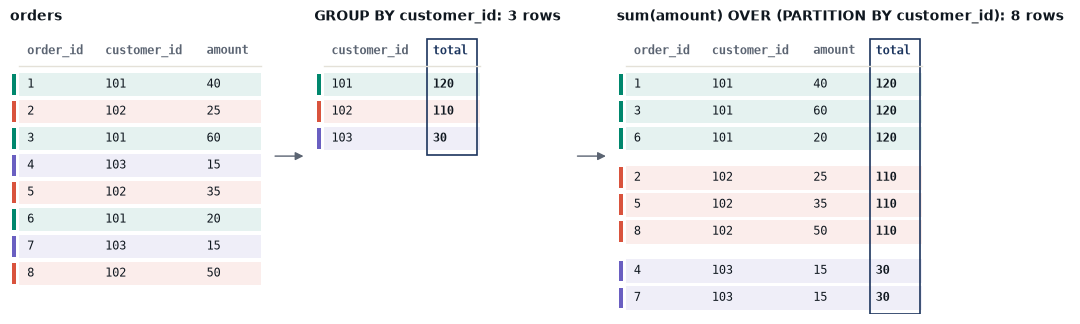

In [39]:
V.table_steps([
    {"title": "orders", "df": con.sql("SELECT order_id, customer_id, amount FROM orders ORDER BY order_id").df()},
    {"title": "GROUP BY customer_id: 3 rows",
     "df": con.sql("SELECT customer_id, sum(amount) AS total FROM orders GROUP BY ALL ORDER BY 1").df(), "new": ["total"]},
    {"title": "sum(amount) OVER (PARTITION BY customer_id): 8 rows",
     "df": con.sql("""SELECT order_id, customer_id, amount, sum(amount) OVER (PARTITION BY customer_id) AS total
                      FROM orders ORDER BY customer_id, order_id""").df(), "new": ["total"], "gap_by": "customer_id"},
], color_by="customer_id")

**Latest change per customer, step by step.** Partition, order inside each partition, number the rows, then `QUALIFY`
keeps number 1. Nothing is physically re-sorted; the steps are how to think about it.

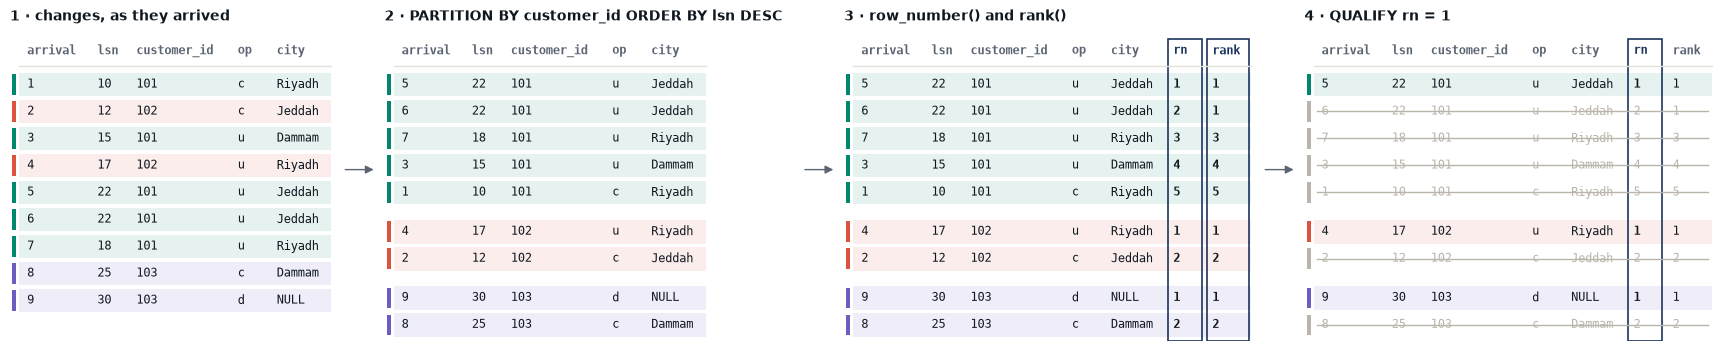

In [40]:
step = con.sql("""
    SELECT arrival, lsn, customer_id, op, city,
           row_number() OVER w AS rn, rank() OVER w AS rank
    FROM changes WINDOW w AS (PARTITION BY customer_id ORDER BY lsn DESC)
    ORDER BY customer_id, lsn DESC, arrival
""").df()
V.table_steps([
    {"title": "1 · changes, as they arrived", "df": con.sql("SELECT arrival, lsn, customer_id, op, city FROM changes ORDER BY arrival").df()},
    {"title": "2 · PARTITION BY customer_id ORDER BY lsn DESC", "df": step.drop(columns=["rn", "rank"]), "gap_by": "customer_id"},
    {"title": "3 · row_number() and rank()", "df": step, "new": ["rn", "rank"], "gap_by": "customer_id"},
    {"title": "4 · QUALIFY rn = 1", "df": step, "new": ["rn"], "faded": step.rn > 1, "gap_by": "customer_id"},
], color_by="customer_id")

**Frames.** For one current row (order 6), the rows each frame lets the aggregate see. `RANGE` (the default) pulls in
order 7 because it has the same date.

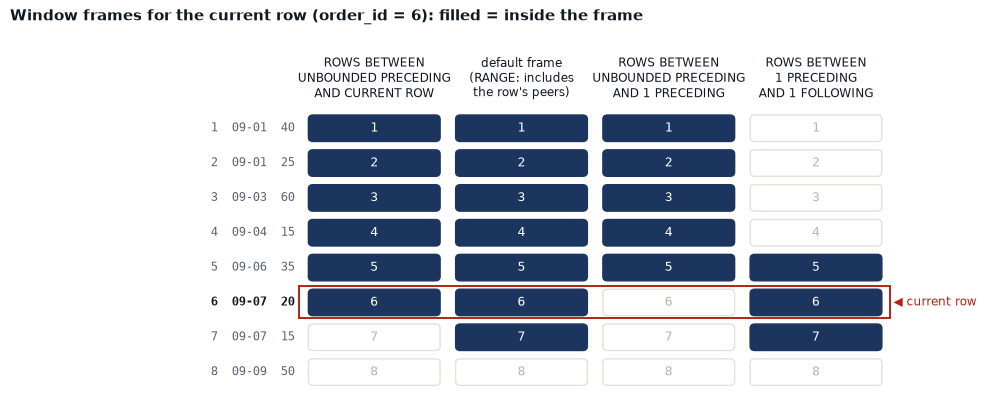

In [41]:
V.frames(frames[["order_id", "created_at", "amount", "rows_running", "default_frame", "before_me", "neighbours"]],
         "order_id", ["rows_running", "default_frame", "before_me", "neighbours"], current=6,
         titles=["ROWS BETWEEN\nUNBOUNDED PRECEDING\nAND CURRENT ROW", "default frame\n(RANGE: includes\nthe row's peers)",
                 "ROWS BETWEEN\nUNBOUNDED PRECEDING\nAND 1 PRECEDING", "ROWS BETWEEN\n1 PRECEDING\nAND 1 FOLLOWING"])

**Logical evaluation order.** Windows are computed after `WHERE`, `GROUP BY` and `HAVING`; `QUALIFY` filters on them.

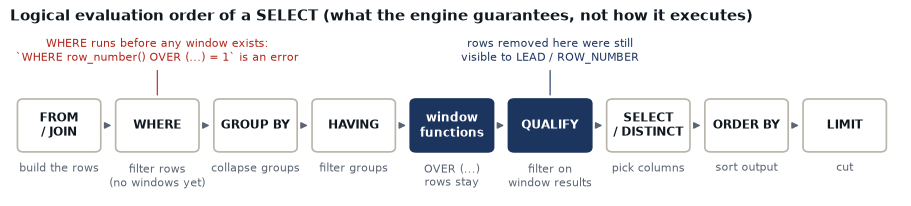

In [42]:
V.evaluation_order()

**A customer's city history.** Each period runs until the next change of the same customer (`lead` by `lsn`). Top: the
correct history; below it, the three ways to get it wrong from §6 and §7.

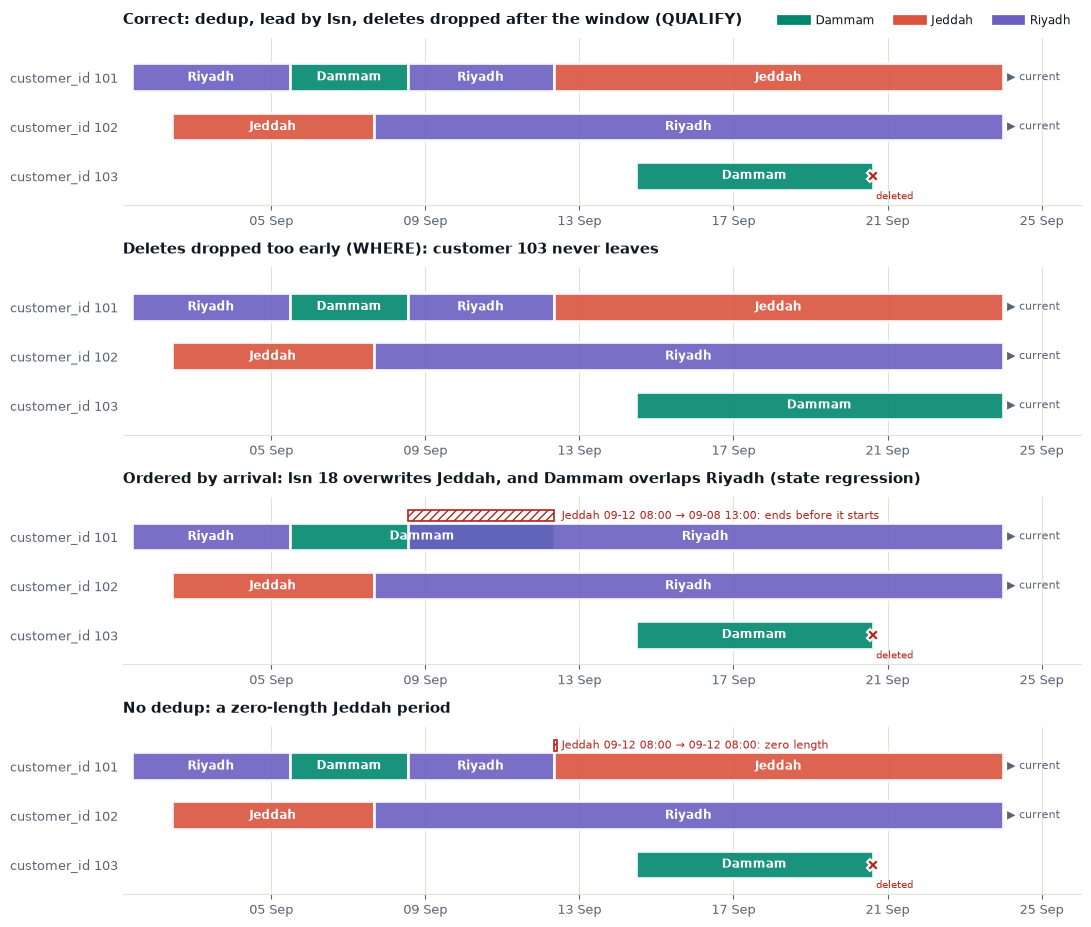

In [43]:
V.timelines([
    ("Correct: dedup, lead by lsn, deletes dropped after the window (QUALIFY)", history),
    ("Deletes dropped too early (WHERE): customer 103 never leaves", too_early),
    ("Ordered by arrival: lsn 18 overwrites Jeddah, and Dammam overlaps Riyadh (state regression)", wrong_order),
    ("No dedup: a zero-length Jeddah period", no_dedup),
], until="2026-09-24")